# BigMart Sales Prediction

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset using summary statistics and visualizations.

In this notebook, we will:
- Examine the distribution of item sales.
- Compare sales across product and outlet categories.
- Investigate relationships between numerical features and sales.
- Identify patterns that may help predict product sales.

We will initially analyze the original training data, because it contains the target variable `Item_Outlet_Sales`.

In [1]:
# Import pandas for data analysis
import pandas as pd

# Import matplotlib for creating charts
import matplotlib.pyplot as plt

# Load the original training dataset
train = pd.read_csv("../data/raw/Train.csv")

# Display the first five rows
train.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


### 3.1 Sales Summary Statistics

We will calculate summary statistics for `Item_Outlet_Sales` to understand the typical sales value, variation, and range.

This provides an initial understanding of the target variable we want to predict.

In [2]:
# Display summary statistics for item outlet sales
train["Item_Outlet_Sales"].describe()

count     8523.000000
mean      2181.288914
std       1706.499616
min         33.290000
25%        834.247400
50%       1794.331000
75%       3101.296400
max      13086.964800
Name: Item_Outlet_Sales, dtype: float64

### 3.2 Distribution of Item Outlet Sales

A histogram shows how frequently sales values occur within different ranges.

We will use a histogram to see whether sales are concentrated in a particular range or whether a small number of products have much higher sales.

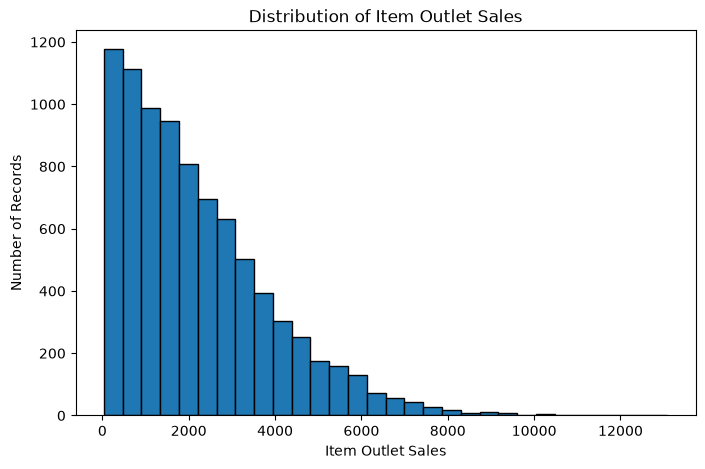

In [3]:
# Plot the distribution of item outlet sales
plt.figure(figsize=(8, 5))
plt.hist(train["Item_Outlet_Sales"], bins=30, edgecolor="black")

# Add the chart title and axis labels
plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.ylabel("Number of Records")

# Display the chart
plt.show()

### 3.3 Interpretation of the Sales Distribution

The histogram shows that `Item_Outlet_Sales` is strongly right-skewed. Most records have relatively low sales values, while the number of records decreases as sales increase. A small number of records have much higher sales, creating a long tail that extends to approximately 13,000.

This indicates that high-sales records are less common than low-sales records. The skewed distribution and extreme values should be considered during preprocessing and modeling. A log transformation of the target variable may help reduce the skewness of the distribution.

### 3.4 Average Sales by Outlet Type

Different outlet types may have different sales patterns. We will calculate the average `Item_Outlet_Sales` for each `Outlet_Type` and display the results in a bar chart.

This will help us understand whether outlet type is associated with differences in average sales.

Outlet_Type
Grocery Store         339.828500
Supermarket Type1    2316.181148
Supermarket Type2    1995.498739
Supermarket Type3    3694.038558
Name: Item_Outlet_Sales, dtype: float64


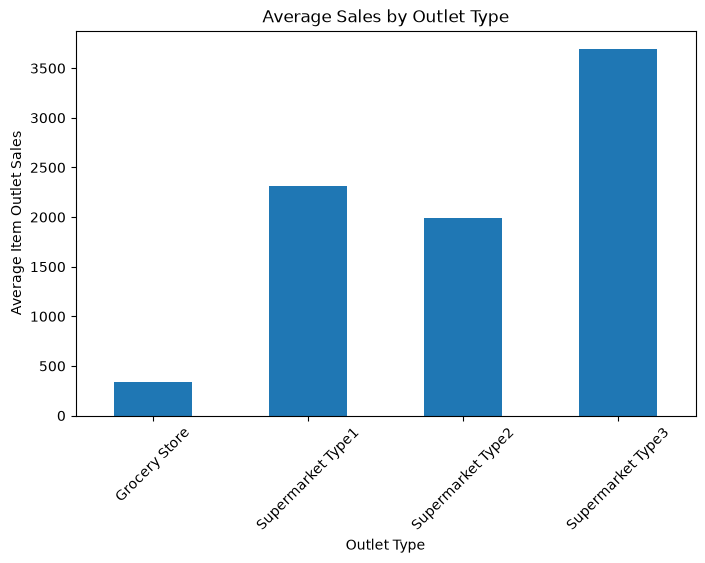

In [4]:
# Calculate average sales for each outlet type
avg_sales = train.groupby("Outlet_Type")["Item_Outlet_Sales"].mean()

# Display average sales
print(avg_sales)

# Create a bar chart
avg_sales.plot(kind="bar", figsize=(8, 5))

# Add chart labels
plt.title("Average Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Average Item Outlet Sales")
plt.xticks(rotation=45)

# Display the chart
plt.show()

### 3.5 Interpretation of Average Sales by Outlet Type

The analysis shows that Supermarket Type3 has the highest average `Item_Outlet_Sales`, at approximately 3,694.04. Grocery Store has the lowest average sales, at approximately 339.83. Supermarket Type1 has average sales of 2,316.18, while Supermarket Type2 has average sales of 1,995.50.

These results suggest that outlet type is associated with differences in average sales. Therefore, `Outlet_Type` may be a useful feature for predicting sales. However, these results show an association and do not prove that outlet type alone causes higher or lower sales.

### 3.6 Average Sales by Product Category

Different product categories may have different average sales. We will calculate the average `Item_Outlet_Sales` for each `Item_Type` and visualize the results using a bar chart.

Item_Type
Starchy Foods            2374.332773
Seafood                  2326.065928
Fruits and Vegetables    2289.009592
Snack Foods              2277.321739
Household                2258.784300
Dairy                    2232.542597
Canned                   2225.194904
Breads                   2204.132226
Meat                     2158.977911
Hard Drinks              2139.221622
Frozen Foods             2132.867744
Breakfast                2111.808651
Health and Hygiene       2010.000265
Soft Drinks              2006.511735
Baking Goods             1952.971207
Others                   1926.139702
Name: Item_Outlet_Sales, dtype: float64


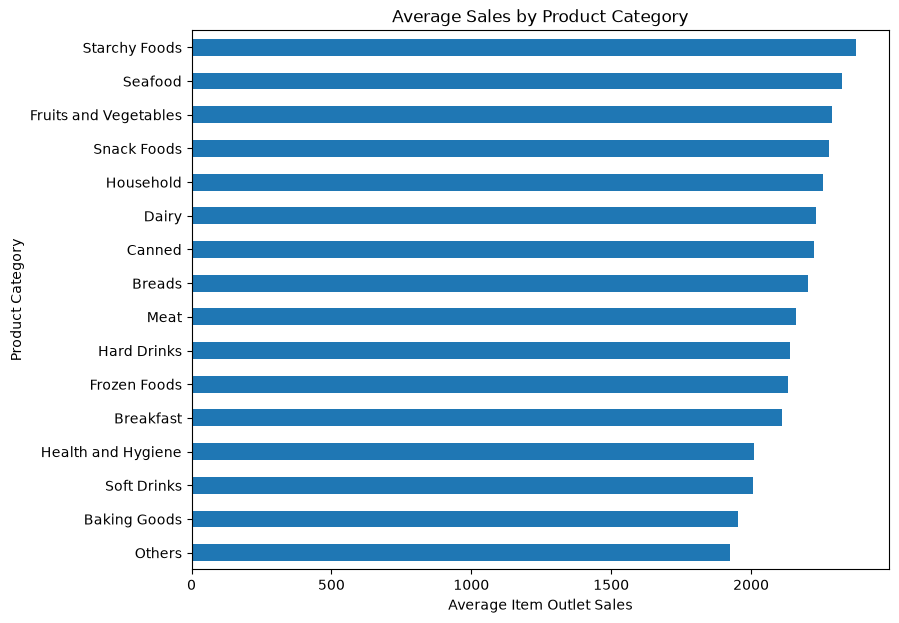

In [5]:
# Calculate average sales for each product category
avg_item_sales = train.groupby("Item_Type")["Item_Outlet_Sales"].mean()

# Display average sales
print(avg_item_sales.sort_values(ascending=False))

# Plot average sales by product category
avg_item_sales.sort_values().plot(kind="barh", figsize=(9, 7))

# Add chart labels
plt.title("Average Sales by Product Category")
plt.xlabel("Average Item Outlet Sales")
plt.ylabel("Product Category")

# Display the chart
plt.show()

### 3.7 Interpretation of Average Sales by Product Category

The analysis shows that Starchy Foods has the highest average `Item_Outlet_Sales`, at approximately 2,374.33, followed by Seafood at approximately 2,326.07. The Others category has the lowest average sales, at approximately 1,926.14.

Fruits and Vegetables and Snack Foods also show relatively high average sales. These findings suggest that product category may help explain differences in sales. However, average sales alone do not indicate total category revenue or prove that a particular category causes higher sales.

### 3.8 Relationship Between Item MRP and Sales

`Item_MRP` represents the maximum retail price of an item. We will use a scatter plot to examine the relationship between item price and outlet sales.

This may help us understand whether items with higher retail prices tend to have higher sales values.

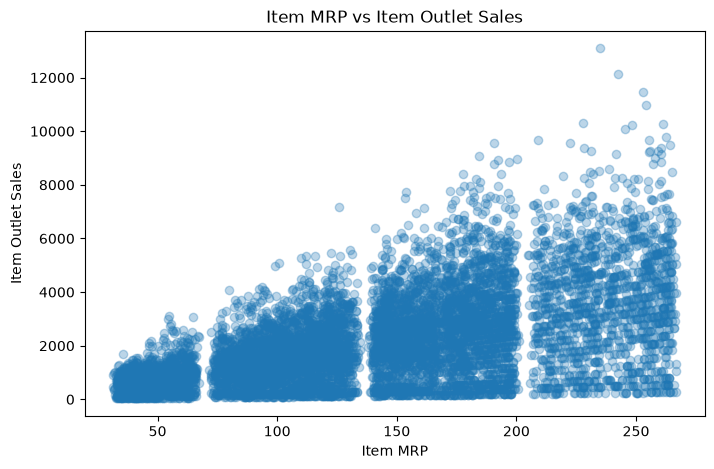

In [6]:
# Create a scatter plot of item price and sales
plt.figure(figsize=(8, 5))
plt.scatter(train["Item_MRP"], train["Item_Outlet_Sales"], alpha=0.3)

# Add chart labels
plt.title("Item MRP vs Item Outlet Sales")
plt.xlabel("Item MRP")
plt.ylabel("Item Outlet Sales")

# Display the chart
plt.show()

### 3.9 Interpretation of Item MRP and Sales

The scatter plot shows a generally positive relationship between `Item_MRP` and `Item_Outlet_Sales`. Records with higher MRP values tend to have higher sales values, and the highest sales values are mostly observed at higher price levels.

However, the points are widely spread at each price level. This suggests that MRP alone does not explain sales differences. Other factors, such as product category, outlet characteristics, item visibility, and demand, may also contribute to sales variation. The grouped bands in the plot may reflect repeated or discrete MRP values in the dataset.

These observations suggest that `Item_MRP` may be a useful feature for predicting `Item_Outlet_Sales`, although further analysis is needed to measure the strength of this relationship.

### 3.10 Relationship Between Item Visibility and Sales

`Item_Visibility` represents the proportion of the total display area in a store allocated to a particular item. We will use a scatter plot to explore the relationship between item visibility and outlet sales.

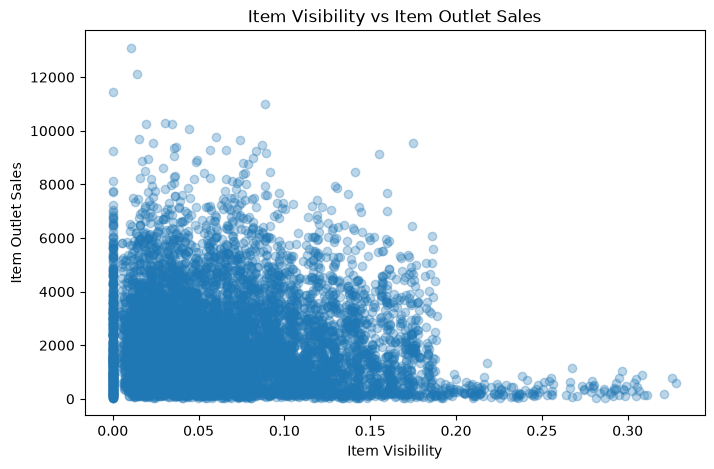

In [7]:
# Create a scatter plot of item visibility and sales
plt.figure(figsize=(8, 5))
plt.scatter(train["Item_Visibility"], train["Item_Outlet_Sales"], alpha=0.3)

# Add chart labels
plt.title("Item Visibility vs Item Outlet Sales")
plt.xlabel("Item Visibility")
plt.ylabel("Item Outlet Sales")

# Display the chart
plt.show()

### 3.11 Interpretation of Item Visibility and Sales

The scatter plot suggests a weak negative relationship between `Item_Visibility` and `Item_Outlet_Sales`. Most observations have low visibility values, but their sales vary widely. Higher visibility values do not consistently correspond to higher sales.

The wide spread of points suggests that item visibility alone may not explain sales differences. The concentration of values at zero or near-zero visibility should also be investigated during data cleaning. Zero visibility may represent an unusual measurement, but it should not automatically be treated as missing data without further investigation.

These findings suggest that `Item_Visibility` may be useful for prediction, but its relationship with sales requires further analysis.

### 3.12 Investigating Zero Item Visibility

Some records have an `Item_Visibility` value of zero. We will count these records and compare their average sales with records whose visibility is greater than zero.

This investigation will help us decide whether zero visibility deserves further attention during preprocessing.

In [8]:
# Count records with zero visibility
zero_count = (train["Item_Visibility"] == 0).sum()

# Calculate average sales for zero and positive visibility
visibility_sales = train.groupby(
    train["Item_Visibility"] == 0
)["Item_Outlet_Sales"].mean()

# Display the results
print("Records with zero visibility:", zero_count)
print("Percentage with zero visibility:", round(zero_count / len(train) * 100, 2), "%")
print("\nAverage sales by visibility group:")
print(visibility_sales)

Records with zero visibility: 526
Percentage with zero visibility: 6.17 %

Average sales by visibility group:
Item_Visibility
False    2178.575445
True     2222.542928
Name: Item_Outlet_Sales, dtype: float64


### 3.13 Interpretation of Zero Item Visibility

The analysis shows that 526 training records, representing 6.17% of the dataset, have zero `Item_Visibility`. The average sales for these records are approximately 2,222.54, compared with 2,178.58 for records with positive visibility.

The difference in average sales is relatively small. Therefore, zero visibility does not appear to be associated with a large difference in average sales in this simple comparison. However, this analysis does not establish a causal relationship.

Zero visibility values should be investigated further before deciding whether to retain or transform them during preprocessing.

### 3.14 Average Sales by Outlet Location Type

The dataset contains an `Outlet_Location_Type` feature that categorizes outlets by location type. We will calculate average sales for each location type and visualize the results using a bar chart.

Outlet_Location_Type
Tier 1    1876.909159
Tier 2    2323.990559
Tier 3    2279.627651
Name: Item_Outlet_Sales, dtype: float64


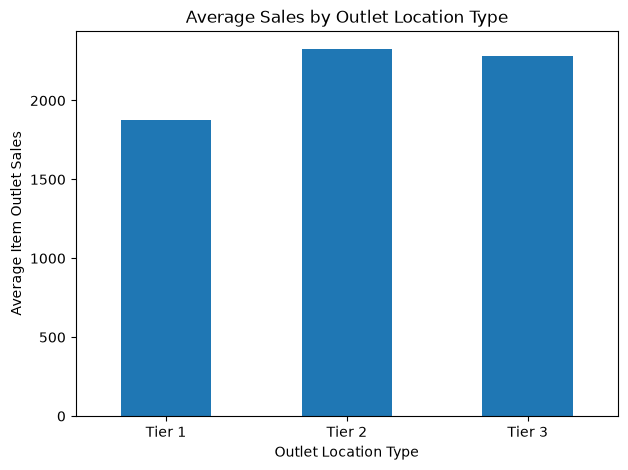

In [9]:
# Calculate average sales by outlet location type
location_sales = train.groupby(
    "Outlet_Location_Type"
)["Item_Outlet_Sales"].mean()

# Display average sales
print(location_sales)

# Create a bar chart
location_sales.plot(kind="bar", figsize=(7, 5))

# Add chart labels
plt.title("Average Sales by Outlet Location Type")
plt.xlabel("Outlet Location Type")
plt.ylabel("Average Item Outlet Sales")
plt.xticks(rotation=0)

# Display the chart
plt.show()

### 3.15 Interpretation of Average Sales by Outlet Location Type

The analysis shows that Tier 2 outlets have the highest average `Item_Outlet_Sales`, at approximately 2,323.99, followed by Tier 3 at 2,279.63. Tier 1 outlets have the lowest average sales, at approximately 1,876.91.

These findings suggest that average sales differ across outlet location types. Therefore, `Outlet_Location_Type` may be a useful feature for predicting sales. However, this comparison alone does not establish that location type causes differences in sales.

### 3.16 Outlet Establishment Year and Sales

The `Outlet_Establishment_Year` feature records the year each outlet was established. We will calculate average sales for each establishment year and visualize the results.

This analysis can help us explore whether sales differ among outlets established in different years.

Outlet_Establishment_Year
1985    2483.677474
1987    2298.995256
1997    2277.844267
1998     339.351662
1999    2348.354635
2002    2192.384798
2004    2438.841866
2007    2340.675263
2009    1995.498739
Name: Item_Outlet_Sales, dtype: float64


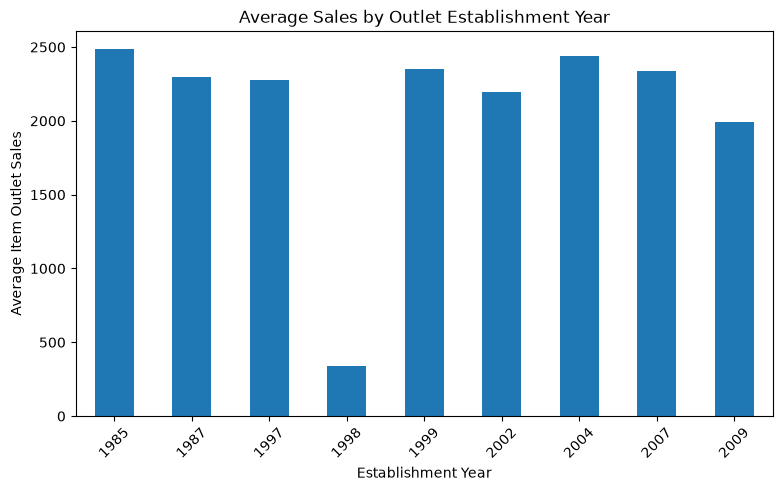

In [10]:
# Calculate average sales by establishment year
year_sales = train.groupby(
    "Outlet_Establishment_Year"
)["Item_Outlet_Sales"].mean()

# Display average sales
print(year_sales.sort_index())

# Create a bar chart
year_sales.sort_index().plot(kind="bar", figsize=(9, 5))

# Add chart labels
plt.title("Average Sales by Outlet Establishment Year")
plt.xlabel("Establishment Year")
plt.ylabel("Average Item Outlet Sales")
plt.xticks(rotation=45)

# Display the chart
plt.show()

### 3.17 Interpretation of Outlet Establishment Year and Sales

The analysis shows that outlets established in 1985 have the highest average `Item_Outlet_Sales`, at approximately 2,483.68. Outlets established in 1998 have the lowest average sales, at approximately 339.35. Most other establishment years have average sales between approximately 1,995 and 2,439.

The unusually low average for 1998 deserves further investigation. Establishment year may be associated with outlet characteristics, so these differences should not be interpreted as evidence that the establishment year itself causes higher or lower sales.

Overall, `Outlet_Establishment_Year` may provide useful information for prediction, but its relationship with outlet type and other features should also be considered.

### 3.18 Average Sales by Individual Outlet

We will calculate the average `Item_Outlet_Sales` for each `Outlet_Identifier`. This comparison will help us identify outlets with particularly high or low average sales.

Outlet_Identifier
OUT027    3694.038558
OUT035    2438.841866
OUT049    2348.354635
OUT017    2340.675263
OUT013    2298.995256
OUT046    2277.844267
OUT045    2192.384798
OUT018    1995.498739
OUT019     340.329723
OUT010     339.351662
Name: Item_Outlet_Sales, dtype: float64


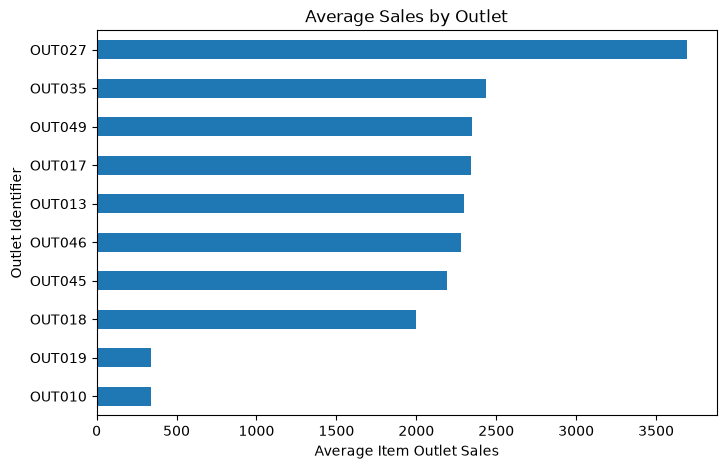

In [11]:
# Calculate average sales for each outlet
outlet_sales = train.groupby(
    "Outlet_Identifier"
)["Item_Outlet_Sales"].mean()

# Display average sales from highest to lowest
print(outlet_sales.sort_values(ascending=False))

# Plot average sales by outlet
outlet_sales.sort_values().plot(kind="barh", figsize=(8, 5))

# Add chart labels
plt.title("Average Sales by Outlet")
plt.xlabel("Average Item Outlet Sales")
plt.ylabel("Outlet Identifier")

# Display the chart
plt.show()

### 3.19 Interpretation of Average Sales by Individual Outlet

The analysis shows that OUT027 has the highest average `Item_Outlet_Sales`, at approximately 3,694.04. OUT010 has the lowest average sales, at approximately 339.35, followed closely by OUT019 at approximately 340.33.

The substantial differences between outlets suggest that outlet characteristics may be important for predicting sales. In particular, OUT010 and OUT019 have much lower average sales than the other outlets. Their outlet types and other characteristics should be considered when interpreting these results.

These findings also help explain why the establishment-year comparison showed unusually low average sales for 1998: the year is associated with OUT010 in this dataset. The difference may reflect the outlet's characteristics rather than the establishment year itself.

### 3.20 Correlation Analysis

Correlation analysis helps us understand the strength and direction of the linear relationship between numerical variables.

In this section, we will:
- Calculate correlations between numerical features.
- Examine how numerical features relate to `Item_Outlet_Sales`.
- Visualize the correlations using a heatmap.

Correlation does not prove causation, and a weak linear correlation does not necessarily mean that a feature is useless for prediction.

In [12]:

# Select numerical columns from the training dataset
numeric_data = train.select_dtypes(include="number")

# Calculate correlations between numerical columns
correlation = numeric_data.corr()

# Display correlations with sales
print(correlation["Item_Outlet_Sales"].sort_values(ascending=False))


Item_Outlet_Sales            1.000000
Item_MRP                     0.567574
Item_Weight                  0.014123
Outlet_Establishment_Year   -0.049135
Item_Visibility             -0.128625
Name: Item_Outlet_Sales, dtype: float64


### 3.21 Interpretation of Correlation Analysis

The correlation analysis shows that `Item_MRP` has the strongest linear relationship with `Item_Outlet_Sales`, with a correlation coefficient of approximately 0.568. This indicates a moderate positive relationship between item price and sales.

`Item_Weight` has a correlation of approximately 0.014, indicating almost no linear relationship with sales. `Outlet_Establishment_Year` has a very weak negative correlation of approximately -0.049, while `Item_Visibility` has a weak negative correlation of approximately -0.129.

These results suggest that `Item_MRP` may be a useful numerical feature for sales prediction. However, correlation alone is not enough to decide which features to keep because categorical variables and interactions between features may also provide predictive information.

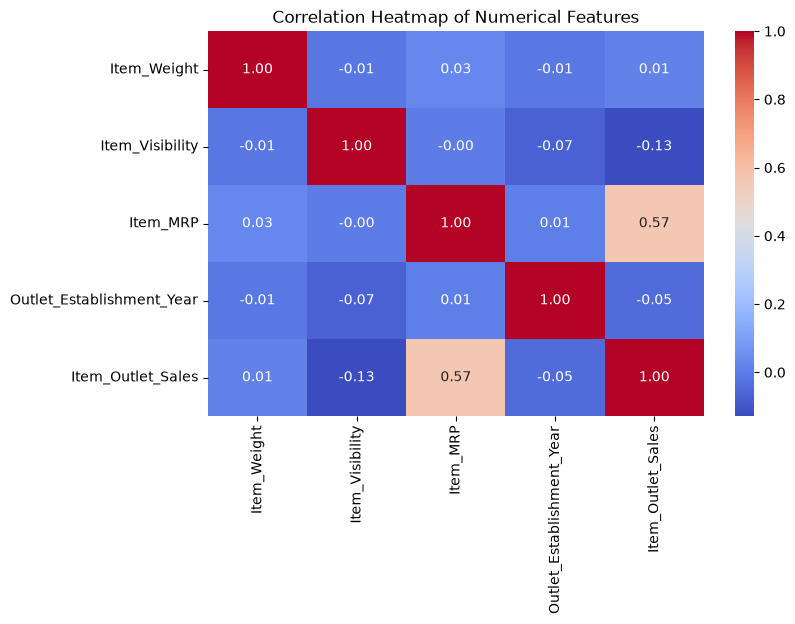

In [13]:

# Import seaborn for the heatmap
import seaborn as sns

# Create the correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

# Add a chart title
plt.title("Correlation Heatmap of Numerical Features")

# Display the heatmap
plt.show()


### 3.22 Interpretation of the Correlation Heatmap

The heatmap visualizes the correlation coefficients between the numerical features. `Item_MRP` has the strongest relationship with `Item_Outlet_Sales`, with a moderate positive correlation of approximately `0.57`. This suggests that higher-priced items tend to have higher sales.

`Item_Visibility` has a weak negative correlation with sales of approximately `-0.13`, while `Outlet_Establishment_Year` has a very weak negative correlation of approximately `-0.05`. `Item_Weight` has almost no linear relationship with sales, at approximately `0.01`.

The correlations among the predictor variables are also close to zero, so there is little evidence of strong multicollinearity among these numerical features. However, the heatmap only shows linear relationships and does not capture interactions or patterns involving categorical variables.

### 3.23 Summary of Exploratory Data Analysis

The exploratory data analysis provided several useful insights into the BigMart sales dataset.

- **Sales distribution:** `Item_Outlet_Sales` is right-skewed, with a small number of records having very high sales values.
- **Outlet type:** Supermarket Type3 has the highest average sales, while Grocery Stores have the lowest.
- **Product category:** Starchy Foods has the highest average sales among the product categories examined.
- **Item MRP:** `Item_MRP` has a moderate positive correlation with `Item_Outlet_Sales`, making it a potentially useful numerical feature.
- **Item visibility:** `Item_Visibility` has a weak negative correlation with sales. Zero visibility values should be investigated before deciding how to handle them.
- **Outlet characteristics:** Average sales differ substantially across outlets, suggesting that outlet-related features may help predict sales.
- **Numerical correlations:** The numerical features show little evidence of strong pairwise linear relationships with one another.

Overall, the EDA suggests that item price, product characteristics, and outlet characteristics may contribute to sales prediction. These observations will guide the next stage: data preprocessing and machine-learning model development.

The patterns identified during EDA are exploratory findings. Their usefulness must be evaluated using an appropriate validation strategy and regression metrics.